# RW2 - modelo sólido con barras embebidas

Espécimen **RW2**, Thomsen y Wallace (1995). Corresponde al mismo muro de `rw2_stko.ipynb`
(1220 x 3660, t = 102, elementos de borde de 200 mm, bloque de base de 500 mm a cada lado
y 500 mm de profundidad, carga axial de 372.8 kN), construido con **hexaedros**
(`LadrunoBrick`, formulación `brick`) y **barras discretas** embebidas en el hormigón
(`LadrunoEmbeddedRebar`, adherencia perfecta, barras `CorotTruss`). Unidades **N, mm, MPa**.

| Elemento | Definición en este modelo | Fuente |
|---|---|---|
| Muro | 1220 x 3660 x 102, elementos de borde de 200 mm, división en z = 1220 (zona confinada) | PEER 607, sec. 7.1.1, Fig. 7.1-7.3 |
| Pedestal | 1930 x 690 x 102, un volumen elástico, E x (500 / 102) para reproducir la rigidez en el plano de la base de referencia | PEER 607, Fig. 7.2; E de referencia |
| Hormigón | `ASDConcrete3D`, preajuste `Concrete (9P)` de STKO, sin confinar 42.8 MPa / confinado 47.6 MPa; los valores sin información publicada conservan la calibración STKO de referencia | PEER 607, Tablas 7.1-7.2 |
| Barras de borde | 8 #3 (db 9.53) por extremo, 3 @ 51 desde 19 mm, dos capas 19 / 64 / 19 | PEER 607, Fig. 7.3a |
| Barras del alma | #2 (db 6.35) @ 191, dos cortinas, verticales y horizontales | PEER 607, Fig. 7.3a |
| Estribos | Alambre de 4.76 mm @ 76 en los 1220 mm inferiores (`lw`) | PEER 607, sec. 7.1.1, Fig. 7.3a |
| Acero | `Hysteretic` por tipo de barra, #3 434 / 505 al 2 % / 641 al 10 %; #2 y alambre 448 / 519 / 586 al 8 %; parámetros de estrangulamiento (pinching) 0.6 / 0.8 | Tabla 7.1, PEER 2024/11, Tabla A.1; pinching de referencia |
| Protocolo | 40 puntos de inversión del registro de ensayo, incrementos de 0.5 mm | Archivo de ensayo (como en `rw2_specimen`) |

En Windows se ejecuta con `OpenSeesMP` de Ladruno en **un proceso**. La versión instalada
de apeGmsh carece de soporte para exportar los vínculos de barras embebidas con MPI particionado.
Se conservan las entradas del modelo y el historial de carga.
Utilizar el kernel `C:\venv\opensees_venv\Scripts\python.exe`.
El respaldo de cada valor se encuentra en `context/`.

## Orden de trabajo

- **CONFIGURACIÓN DE CORRIDAS Y MEDICIONES:** al final de la celda de entradas.
- **CREAR CORRIDA Y CONGELAR PARÁMETROS:** antes de generar el Tcl.
- **EJECUTAR CORRIDA:** ejecuta una sola vez cada carpeta `runs/wallace_NNNN`.
- **COMPARACIONES LOCALES:** bloque final, independiente de la construcción del modelo.
- **EXPORTAR Y ACTUALIZAR FICHA:** última celda; guarda datos, PNG/PDF y fichas Markdown.

Las corridas anteriores se conservan. Los datos locales proceden de gráficas publicadas digitalizadas;
las limitaciones de medición se documentan en `DatosExperimentales/README.md` y en cada ficha.


In [1]:
import math
import os
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from apeGmsh import apeGmsh, Results
from apeGmsh.opensees import apeSees
from apeGmsh.rebar import Cage

notebook_dir = Path(r'D:\OneDrive\Escritorio\AHORA SI\Notebooks\RW2_Wallace')
opensees_mp = Path(r'C:\OpenSees-Solvers\opensees-bin\OpenSeesMP.exe')
launcher = Path(r'C:\OpenSees-Solvers\openseesmp.bat')
nparts = 1  # La versión instalada de apeGmsh carece de soporte para exportar barras embebidas con MPI particionado.
runs_dir = notebook_dir / 'runs'
if str(notebook_dir) not in sys.path:
    sys.path.insert(0, str(notebook_dir))
import rw2_workflow as rw2
exp_file = notebook_dir / 'DatosExperimentales' / 'ExperimentalData.csv'  # m, tonf

for required in (opensees_mp, launcher, exp_file):
    if not required.is_file():
        raise FileNotFoundError(required)
print('Python:', sys.executable)
print('experiment:', exp_file)
print('historial de corridas:', runs_dir)



 █████╗ ██████╗ ███████╗ ██████╗ ███╗   ███╗███████╗██╗  ██╗
██╔══██╗██╔══██╗██╔════╝██╔════╝ ████╗ ████║██╔════╝██║  ██║
███████║██████╔╝█████╗  ██║  ███╗██╔████╔██║███████╗███████║
██╔══██║██╔═══╝ ██╔══╝  ██║   ██║██║╚██╔╝██║╚════██║██╔══██║
██║  ██║██║     ███████╗╚██████╔╝██║ ╚═╝ ██║███████║██║  ██║
╚═╝  ╚═╝╚═╝     ╚══════╝ ╚═════╝ ╚═╝     ╚═╝╚══════╝╚═╝  ╚═╝
██╗      █████╗ ██████╗ ██████╗ ██╗   ██╗███╗   ██╗ ██████╗
██║     ██╔══██╗██╔══██╗██╔══██╗██║   ██║████╗  ██║██╔═══██╗
██║     ███████║██║  ██║██████╔╝██║   ██║██╔██╗ ██║██║   ██║
██║     ██╔══██║██║  ██║██╔══██╗██║   ██║██║╚██╗██║██║   ██║
███████╗██║  ██║██████╔╝██║  ██║╚██████╔╝██║ ╚████║╚██████╔╝
╚══════╝╚═╝  ╚═╝╚═════╝ ╚═╝  ╚═╝ ╚═════╝ ╚═╝  ╚═══╝ ╚═════╝
  apeGmsh v2.0.0



Python: c:\venv\opensees_venv\Scripts\python.exe
experiment: D:\OneDrive\Escritorio\AHORA SI\Notebooks\RW2_Wallace\ExperimentalData.txt
historial de corridas: D:\OneDrive\Escritorio\AHORA SI\Notebooks\RW2_Wallace\runs


## Datos de entrada (N, mm, MPa)


In [2]:
# geometría, PEER 2006/07, sec. 7.1.1, Fig. 7.2-7.3a (igual que en rw2_specimen)
lw = 1220.0          # longitud del muro
hw = 3660.0          # altura del muro
tw = 102.0           # espesor del muro (dirección y, centrado en y = 0)
lbe = 200.0          # ancho del elemento de borde
h_conf = 1220.0      # altura de la zona de borde confinada (estribos @ 76), = lw
max_size = 200.0     # tamaño máximo de elemento finito (igual que en los modelos de láminas del espécimen)
brick = 'ssp'        # formulación LadrunoBrick, std (= stdBrick) | bbar | ssp (un punto estabilizado, sin bloqueo por flexión) | eas
bar_refine = 4       # malla de barras = max_size / bar_refine (4 veces más fina que la del hormigón)
base_overhang = (1930.0 - lw) / 2    # pedestal de 1.93 m de longitud
base_depth = 690.0                   # pedestal de 0.69 m de profundidad
record_all = True    # True incluye todos los nodos del hormigón (visor y vistas isométricas); False incluye solo los nodos cargados (corridas de calibración)

# hormigón, valores del espécimen (Tablas 7.1-7.2); los valores sin información publicada conservan la calibración STKO de referencia
ec = 31030.0                            # Tablas 7.1-7.2
nu = 0.2
ft = 2.03                               # Tabla 7.1
fcp_unconf, ecp_unconf = 42.8, 0.0021   # Tabla 7.2, alma de RW2 (sin confinar)
fcp_conf, ecp_conf = 47.6, 0.0033       # Tabla 7.2, borde de RW2 (confinado)
gt = 0.073 * fcp_unconf ** 0.18         # N/mm, Código Modelo fib 2010 (sin valor publicado para el ensayo)
fc0, fcr, gc = 10.0, 10.0, 36.0         # referencia (STKO 01_Wallace)
pscale_t = pscale_c = 0.3               # referencia

# pedestal elástico, placa de referencia E = 28198, h = 500; se conserva E*h sobre el espesor del muro
base_e = 28198.0 * 500.0 / tw

steel_e2 = 0.02                       # segundo punto de la envolvente del acero

# acero, fy, E, b de la Tabla 7.1; fu, eu de PEER 2024/11, Tabla A.1 (como en rw2_specimen)
es = 200000.0
b_h = 0.02
fy3, fu3, eu3 = 434.0, 641.0, 0.10     # #3
fy2, fu2, eu2 = 448.0, 586.0, 0.08     # #2; el alambre de los estribos también fue recocido hasta aproximadamente 448 (sec. 7.1.2)
s2_3 = fy3 + b_h * es * (steel_e2 - fy3 / es)     # tensión al 2 % con razón de endurecimiento b
s2_2 = fy2 + b_h * es * (steel_e2 - fy2 / es)
pinch_x, pinch_y = 0.6, 0.8            # referencia (STKO 01_Wallace)

# barras, Fig. 7.3a
db3, db2, dbw = 9.53, 6.35, 4.76     # #3 de borde, #2 del alma, alambre de estribos
edge = 19.0                          # distancia del centro de la barra a la cara, en longitud y espesor
be_step = 51.0                       # barras de borde 3 @ 51
web_step = 191.0                     # barras del alma 3 @ 191 (verticales) y @ 191 (horizontales)
hoop_step = 76.0
anchor_depth = base_depth - 50.0     # profundidad de anclaje de las barras verticales en el pedestal (artículo con ganchos de 90 grados)
k_perfect = 1.0e8                    # penalización axial de adherencia perfecta de LadrunoEmbeddedRebar

# cargas
p_axial = 0.07 * lw * tw * fcp_unconf   # N, 0.07 Ag f'c (PEER 607, sec. 6.1) = 372.8 kN
gamma_c = 2.4e-9 * 9810.0               # N/mm3, peso propio

print(f'axial {p_axial / 1e3:.1f} kn | base e {base_e:.0f} mpa | gt {gt:.3f} n/mm')
print(f'steel #3 {fy3} / {s2_3:.1f} / {fu3} | #2 {fy2} / {s2_2:.1f} / {fu2} mpa')

# ============================================================
# CONFIGURACIÓN DE CORRIDAS Y MEDICIONES LOCALES
# Se captura automáticamente al generar cada nuevo Tcl.
# ============================================================
run_notes = ''                    # objetivo/cambio que quieres identificar en la ficha
record_local = True               # acero + hormigón internos; mantiene también nodos de hormigón
concrete_implex = True            # mismo valor que el modelo actual
steel_damage1 = 0.0
steel_damage2 = 0.0
steel_beta = 0.0
n_gravity = 10
gravity_tol, gravity_max_iter = 1e-4, 50
cyclic_tol, cyclic_max_iter = 1e-4, 100
krylov_max_dim = 10
strategy_name = 'penalty-stiff'

# Sensores virtuales: longitudes en mm; z se mide desde la interfaz muro-pedestal.
lvdt_z0_mm = 0.0                  # supuesto de inicio de la longitud de medición
lvdt_length_mm = 229.0            # Fig. 7.30
steel_base_z_mm = 25.0
steel_story_z_mm = 950.0
concrete_gage_z_mm = 92.0
concrete_gage_length_mm = 83.0    # Fig. 7.32; x=25 mm supuesto del borde sur
rotation_height_mm = 760.0        # Fig. 7.29
story_height_mm = 914.5
shear_alpha = 0.67                # separación flexión/corte, ecuaciones 8.1 y 8.2
strain_reference = 'total'        # 'total' o 'after_gravity'; conservar definición experimental
nominal_drifts_pct = [0.1, 0.25, 0.5, 0.75, 1.0, 1.5, 1.0, 1.5, 2.0, 2.5]

profile_cycle = 1                # seleccion numerica; el ciclo experimental no se especifica


axial 372.8 kn | base e 138225 mpa | gt 0.144 n/mm
steel #3 434.0 / 505.3 / 641.0 | #2 448.0 / 519.0 / 586.0 mpa


## Geometría

Se utiliza la misma disposición x-z de `rw2_stko`, construida sobre la cara y = -tw/2
y extruida a través del espesor. Incluye un rectángulo de base (un grupo físico,
un volumen) y los rectángulos del muro, divididos en z = 1220 para la zona confinada.
`fragment` divide la arista superior de la base bajo el muro y, mediante cuatro puntos,
su arista inferior en las mismas coordenadas x, de modo que la base se malla como
una única región estructurada. `extrude` con capas y `recombine` transforma cada
cuadrilátero en una columna de hexaedros.

| Grupo físico | Volúmenes | Uso |
|---|---|---|
| `Wall_BE_Confined` | Elementos de borde, z de 0 a 1220 | Hormigón confinado |
| `Wall_Unconfined` | Alma y elementos de borde sobre 1220 | Hormigón sin confinar |
| `Base_Block` | Bloque de base | Elástico |
| `Concrete` | Todos los volúmenes | Sólido anfitrión de las barras embebidas |
| `Fixed` | Cara inferior, ambas caras laterales y cara superior expuesta de la base | Apoyos |
| `Top` | Cara superior del muro | Carga axial y desplazamiento impuesto |


In [3]:
g = apeGmsh(model_name='rw2_solid_ladruno_embedment', verbose=False)
g.begin()

x0, x1 = -base_overhang, lw + base_overhang
wall_x = [0.0, lbe, lw - lbe, lw]
y0 = -tw / 2                                 # cara de extrusión; el muro abarca desde y = -tw/2 hasta tw/2

g.model.geometry.add_rectangle(x0, y0, -base_depth, x1 - x0, base_depth, plane='xz', label='base_block')
wall = []
for name, a, b in (('be_left', 0.0, lbe), ('web', lbe, lw - lbe), ('be_right', lw - lbe, lw)):
    for part, za, zb in (('low', 0.0, h_conf), ('up', h_conf, hw)):
        g.model.geometry.add_rectangle(a, y0, za, b - a, zb - za, plane='xz', label=f'{name}_{part}')
        wall.append(f'{name}_{part}')
bottom_pts = [g.model.geometry.add_point(x, y0, -base_depth) for x in wall_x]
g.model.boolean.fragment(['base_block'], wall + [(0, p) for p in bottom_pts], dim=2)

ny = math.ceil(tw / max_size - 1e-9) + 1       # nodos a través del espesor
g.model.transforms.extrude(g.model.select(dim=2).tags(), 0.0, tw, 0.0, num_elements=[ny - 1], recombine=True)

tol = 1e-3
y1 = tw / 2 + tol

def vols_in(lo, hi):
    return g.model.select(dim=3).in_box(lo, hi).tags()

def faces_in(lo, hi):
    return g.model.select(dim=2).in_box(lo, hi).tags()

g.physical.add_volume(vols_in((x0 - tol, y0 - tol, -base_depth - tol), (x1 + tol, y1, tol)), name='Base_Block')
g.physical.add_volume(vols_in((-tol, y0 - tol, -tol), (lbe + tol, y1, h_conf + tol))
                      + vols_in((lw - lbe - tol, y0 - tol, -tol), (lw + tol, y1, h_conf + tol)), name='Wall_BE_Confined')
g.physical.add_volume(vols_in((lbe - tol, y0 - tol, -tol), (lw - lbe + tol, y1, h_conf + tol))
                      + vols_in((-tol, y0 - tol, h_conf - tol), (lw + tol, y1, hw + tol)), name='Wall_Unconfined')
g.physical.add_volume(g.model.select(dim=3).tags(), name='Concrete')

fixed = (faces_in((x0 - tol, y0 - tol, -base_depth - tol), (x1 + tol, y1, -base_depth + tol))   # cara inferior de la base
         + faces_in((x0 - tol, y0 - tol, -base_depth - tol), (x0 + tol, y1, tol))                # cara lateral izquierda
         + faces_in((x1 - tol, y0 - tol, -base_depth - tol), (x1 + tol, y1, tol))                # cara lateral derecha
         + faces_in((x0 - tol, y0 - tol, -tol), (tol, y1, tol))                                  # cara superior expuesta, izquierda
         + faces_in((lw - tol, y0 - tol, -tol), (x1 + tol, y1, tol)))                            # cara superior expuesta, derecha
g.physical.add_surface(fixed, name='Fixed')
g.physical.add_surface(faces_in((-tol, y0 - tol, hw - tol), (lw + tol, y1, hw + tol)), name='Top')

with g.loads.case('selfweight'):
    for grp in ('Wall_BE_Confined', 'Wall_Unconfined'):
        g.loads.volume(grp, force_per_volume=(0.0, 0.0, -gamma_c))

with g.loads.case('axial'):
    g.loads.surface.traction('Top', vector=(0.0, 0.0, -p_axial / (lw * tw)))
rw2_input_signatures = {}

rw2_input_signatures['geometry'] = rw2.input_signature(globals(), 'geometry')


## Armaduras (Fig. 7.3a)

Centros de las barras (x desde el extremo izquierdo del muro, y desde el plano medio del muro).

- **Bordes**. 8 #3 por extremo, x = 19, 70, 121, 172 (y sus posiciones simétricas), y = +-32 (19 / 64 / 19).
- **Armadura vertical del alma**. #2 a 3 @ 191 centradas en el muro, x = 323.5, 514.5, 705.5, 896.5, y = +-32.
- **Armadura horizontal del alma**. #2 @ 191 en altura, x de 19 a 1201, y = +-32 (en el mismo plano que las barras verticales, como idealización de celosía).
- **Estribos**. Rectángulos cerrados de 4.76 mm alrededor de cada grupo de 8 barras, @ 76 desde z = 38 hasta 1220.

Las barras verticales se extienden desde `anchor_depth` dentro de la base hasta 19 mm
bajo la coronación (los ganchos de 90 grados se omiten en el modelo). Todas las barras
utilizan `CorotTruss` con su propia malla de líneas, vinculadas a los hexaedros mediante
`LadrunoEmbeddedRebar` con adherencia perfecta.


In [4]:
yb = tw / 2 - edge                                    # 32 mm
be_x = [edge + j * be_step for j in range(4)]          # 19, 70, 121, 172
web_x = [lw / 2 + (j - 1.5) * web_step for j in range(4)]
z_bot, z_top = -anchor_depth, hw - edge

bars = []

def add_bar(points, db, material, role):
    bars.append(g.rebar.bar(points, db=db, material=material, role=role, name=f'{role}_{len(bars)}'))

for y in (-yb, yb):
    for x in be_x + [lw - x for x in be_x]:
        add_bar([(x, y, z_bot), (x, y, z_top)], db3, 'steel_3', 'vertical')
    for x in web_x:
        add_bar([(x, y, z_bot), (x, y, z_top)], db2, 'steel_2', 'vertical')
    for k in range(1, int(z_top // web_step) + 1):
        z = k * web_step
        add_bar([(edge, y, z), (lw - edge, y, z)], db2, 'steel_2', 'horizontal')

off = (db3 + dbw) / 2                                  # eje del estribo por fuera de las barras
yh = yb + off
z = hoop_step / 2
while z < h_conf:
    for a, b in ((be_x[0] - off, be_x[-1] + off), (lw - be_x[-1] - off, lw - be_x[0] + off)):
        add_bar([(a, -yh, z), (b, -yh, z), (b, yh, z), (a, yh, z), (a, -yh, z)], dbw, 'steel_2', 'tie')
    z += hoop_step

g.rebar.place(Cage(bars=tuple(bars)), into='Concrete', coupling='embedded', perfect=k_perfect,
              emit_elements=True)

n_role = {r: sum(b.role == r for b in bars) for r in ('vertical', 'horizontal', 'tie')}
print('bars:', n_role)
rw2_input_signatures['reinforcement'] = rw2.input_signature(globals(), 'reinforcement')


bars: {'vertical': 24, 'horizontal': 38, 'tie': 32}


C:\Users\mario\AppData\Local\Temp\ipykernel_21164\609688330.py:28: UserWarning: g.rebar.place: embedded coupling uses LadrunoEmbeddedRebar, which is single-process today; partitioned/MPI models must use coupling='conformal'.
  g.rebar.place(Cage(bars=tuple(bars)), into='Concrete', coupling='embedded', perfect=k_perfect,


## Malla

Hexaedros estructurados. En la cara x-z, cada región tiene `n = ceil(length / max_size) + 1`
nodos por lado (la misma regla de `rw2_stko`). La base es una única región transfinita
con sus cuatro esquinas especificadas, y la extrusión genera `ny - 1` capas a través
del espesor. Las barras tienen su propia malla con tamaño `max_size / bar_refine`
(4 veces más fina que la del hormigón).
La malla se divide posteriormente en `nparts` particiones.


In [5]:
def n_nodes(length):
    return math.ceil(length / max_size - 1e-9) + 1

nx_be, nx_web, nx_over = n_nodes(lbe), n_nodes(lw - 2 * lbe), n_nodes(base_overhang)
nz_low, nz_up, nz_base = n_nodes(h_conf), n_nodes(hw - h_conf), n_nodes(base_depth)
print(f'element size: be {lbe / (nx_be - 1):.1f} | web {(lw - 2 * lbe) / (nx_web - 1):.1f} | '
      f'thickness {tw / (ny - 1):.1f} | confined zone {h_conf / (nz_low - 1):.1f} | '
      f'upper wall {(hw - h_conf) / (nz_up - 1):.1f} | overhang {base_overhang / (nx_over - 1):.1f} | '
      f'base depth {base_depth / (nz_base - 1):.1f} mm')

for name, nx in (('be_left', nx_be), ('web', nx_web), ('be_right', nx_be)):
    g.mesh.recipe.structured(f'{name}_low', n=(nx, nz_low), generate=False)
    g.mesh.recipe.structured(f'{name}_up', n=(nx, nz_up), generate=False)

def curves_in(lo, hi):
    return g.model.select(dim=1).in_box(lo, hi).tags()

def point_at(x, z):
    return g.model.select(dim=0).in_box((x - tol, y0 - tol, z - tol), (x + tol, y0 + tol, z + tol)).tags()[0]

spans = [(x0, 0.0, nx_over), (0.0, lbe, nx_be), (lbe, lw - lbe, nx_web), (lw - lbe, lw, nx_be), (lw, x1, nx_over)]
for z in (0.0, -base_depth):                       # aristas superior e inferior de la base, con las mismas divisiones que el muro
    for a, b, n in spans:
        for c in curves_in((a - tol, y0 - tol, z - tol), (b + tol, y0 + tol, z + tol)):
            g.mesh.structured.set_transfinite_curve(c, n)
for x in (x0, x1):                                  # caras laterales de la base
    for c in curves_in((x - tol, y0 - tol, -base_depth - tol), (x + tol, y0 + tol, tol)):
        g.mesh.structured.set_transfinite_curve(c, nz_base)
corners = [point_at(x0, -base_depth), point_at(x1, -base_depth), point_at(x1, 0.0), point_at(x0, 0.0)]
g.mesh.structured.set_transfinite_surface('base_block', corners=corners)
g.mesh.structured.set_recombine('base_block')
g.mesh.sizing.set_global_size(max_size / bar_refine)   # malla de líneas de las barras (los volúmenes son transfinitos)

g.mesh.generation.generate(dim=3)
# La versión instalada de apeGmsh carece de soporte para exportar armaduras embebidas con MPI.
if nparts != 1:
    raise ValueError('This apeGmsh version requires nparts=1 for embedded bars')
fem = g.mesh.queries.get_fem_data(dim=None)

top_ids = [int(n) for n in fem.nodes.select(pg='Top').ids]
print(f'mesh : {fem.info.n_nodes} nodes | {fem.info.n_elems} elems | {nparts} partitions | types {fem.info.types}')
print(f'top nodes {len(top_ids)} | fixed nodes {len(fem.nodes.select(pg="Fixed").ids)} | '
      f'embedded ties {len(g.reinforce.reinforce_records)}')
rw2_input_signatures['mesh'] = rw2.input_signature(globals(), 'mesh')


element size: be 200.0 | web 164.0 | thickness 102.0 | confined zone 174.3 | upper wall 187.7 | overhang 177.5 | base depth 172.5 mm
mesh : 3862 nodes | 4596 elems | 1 partitions | types [ElementTypeInfo('line2', code=1, dim=1, order=1, npe=2, count=3628), ElementTypeInfo('quad4', code=3, dim=2, order=1, npe=4, count=492), ElementTypeInfo('hex8', code=5, dim=3, order=1, npe=8, count=184), ElementTypeInfo('point1', code=15, dim=0, order=0, npe=1, count=292)]
top nodes 16 | fixed nodes 48 | embedded ties 3422


## Corte de sección

Definir `z_cut` y ejecutar para obtener una vista en planta de la malla a esa altura.
Los rectángulos grises representan los hexaedros cortados por el plano (oscuro para
el hormigón confinado, claro para el hormigón sin confinar). Los puntos representan
las barras que atraviesan el plano (barras verticales, dibujadas con su diámetro).
Las líneas representan las barras situadas en el plano dentro de la tolerancia `dz`
(barras horizontales azules, estribos rojos).
Los estribos se ubican en z = 38 + 76 k hasta 1178, y las barras horizontales en z = 191 k.


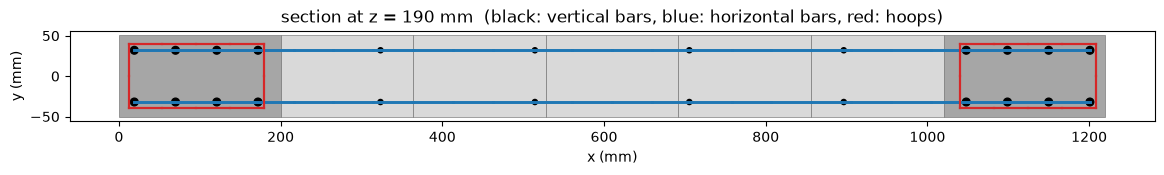

In [6]:
# corte de sección con elementos de hormigón y barras a la altura z_cut
z_cut = 190.0      # mm; en 190 hay un estribo (38 + 2 x 76) y una barra horizontal (191) dentro de dz
dz = 5.0           # las barras situadas en el plano dentro de +-dz se dibujan como líneas

xyz = dict(zip(fem.nodes.ids, fem.nodes.coords))

fig, ax = plt.subplots(figsize=(14, 3))
colors = {'Wall_BE_Confined': '0.65', 'Wall_Unconfined': '0.85', 'Base_Block': '0.95'}
for grp, color in colors.items():
    for conn in fem.elements.select(pg=grp, element_type='hex8').connectivity:
        p = np.array([xyz[n] for n in conn])
        if p[:, 2].min() <= z_cut <= p[:, 2].max():
            ax.add_patch(plt.Rectangle((p[:, 0].min(), p[:, 1].min()), np.ptp(p[:, 0]), np.ptp(p[:, 1]),
                                       facecolor=color, edgecolor='0.4', lw=0.4))

bar_color = {'vertical': 'k', 'horizontal': 'tab:blue', 'tie': 'tab:red'}
for m in g.rebar.placements[0].members:
    for n1, n2 in fem.elements.select(pg=m.pg, element_type='line2').connectivity:
        a, b = np.array(xyz[n1]), np.array(xyz[n2])
        if abs(a[2] - z_cut) <= dz and abs(b[2] - z_cut) <= dz:              # barra situada en el plano de corte
            ax.plot([a[0], b[0]], [a[1], b[1]], color=bar_color[m.role], lw=m.diameter / 3)
        elif min(a[2], b[2]) <= z_cut < max(a[2], b[2]):                     # barra que atraviesa el corte
            t = (z_cut - a[2]) / (b[2] - a[2])
            p = a + t * (b - a)
            ax.add_patch(plt.Circle((p[0], p[1]), m.diameter / 2, color=bar_color[m.role]))

ax.set_aspect('equal')
ax.autoscale_view()
ax.set_xlabel('x (mm)')
ax.set_ylabel('y (mm)')
ax.set_title(f'section at z = {z_cut:.0f} mm  (black: vertical bars, blue: horizontal bars, red: hoops)')
plt.show()

## Visor de la malla


In [7]:
g.mesh.viewer()

## Modelo de OpenSees


In [8]:
ops = apeSees(fem)
ops.model(ndm=3, ndf=3)

def concrete(fcp, ecp):
    # API actual para reproducir la misma ley Concrete (9P) de STKO e IMPL-EX con alfa = 1.
    from apeGmsh.interop.stko.translate_props import asdconcrete_9p
    from apeGmsh.opensees.material.nd import ASDConcrete3D

    law = asdconcrete_9p(dict(
        E=ec, ft=ft, fc0=fc0, fcp=fcp, fcr=fcr, ecp=ecp, Gt=gt, Gc=gc,
        **{'PScale Tension': pscale_t, 'PScale Compression': pscale_c}))
    # El material actual exige daño >= 0; se corrigen únicamente errores de redondeo.
    for key in ('Td', 'Cd'):
        if min(law[key]) < -1e-12:
            raise ValueError(f'Invalid negative damage in {key}')
        law[key] = tuple(max(0.0, value) for value in law[key])
    return ops.register(ASDConcrete3D(E=ec, v=nu, implex=concrete_implex, **law))

conc_unconf = concrete(fcp_unconf, ecp_unconf)
conc_conf = concrete(fcp_conf, ecp_conf)
base_mat = ops.nDMaterial.ElasticIsotropic(E=base_e, nu=nu)

# materiales de barras, Hysteretic simétrico (fluencia, tensión al 2 %, fu en eu), según los nombres utilizados en g.rebar.bar
def hysteretic(fy, e_s, s2, fu, eu, name):
    ey = fy / e_s
    assert ey < steel_e2 < eu and fy < s2 < fu, (fy, s2, fu, eu)
    return ops.uniaxialMaterial.Hysteretic(
        s1p=fy, e1p=ey, s2p=s2, e2p=steel_e2, s3p=fu, e3p=eu,
        s1n=-fy, e1n=-ey, s2n=-s2, e2n=-steel_e2, s3n=-fu, e3n=-eu,
        pinch_x=pinch_x, pinch_y=pinch_y, damage1=steel_damage1, damage2=steel_damage2, beta=steel_beta, name=name)

hysteretic(fy3, es, s2_3, fu3, eu3, 'steel_3')     # barras #3 de borde
hysteretic(fy2, es, s2_2, fu2, eu2, 'steel_2')     # barras #2 del alma y alambre de estribos

ops.element.LadrunoBrick(pg='Wall_Unconfined', material=conc_unconf, formulation=brick)
ops.element.LadrunoBrick(pg='Wall_BE_Confined', material=conc_conf, formulation=brick)
ops.element.LadrunoBrick(pg='Base_Block', material=base_mat, formulation=brick)

ops.fix(pg='Fixed', dofs=(1, 1, 1))
rw2_input_signatures['materials'] = rw2.input_signature(globals(), 'materials')


## Protocolo de carga (40 puntos de inversión del registro de ensayo, como en rw2_specimen)


In [9]:
peaks = [2.34, -2.61, 2.45, -2.38, 5.91, -6.5, 6.11, -6.52, 13.01, -13.7,
         13.84, -13.85, 20.15, -21.22, 20.56, -21.12, 28.52, -29.41, 28.75, -29.71,
         45.52, -46.01, 45.75, -46.12, 29.49, -29.84, 29.34, -29.99, 45.61, -46.12,
         45.27, -46.0, 62.12, -62.09, 62.45, -62.32, 79.85, -79.23, 80.46, -79.57]   # mm
disp_values = [0.0] + peaks
travel = np.cumsum(np.abs(np.diff(disp_values)))       # recorrido acumulado en mm hasta cada pico
time_values = [0.0] + [float(t) for t in travel / travel[-1]]   # pseudotiempo proporcional al recorrido
d_step = 0.5                                      # mm, incremento de desplazamiento
n_cyclic = math.ceil(travel[-1] / d_step)
# mantener el último pico ligeramente después de t = 1; el pseudotiempo acumulado del último incremento puede superar
# ligeramente 1.0, donde la serie Path devuelve 0 (salto de regreso a desplazamiento nulo)
disp_values.append(peaks[-1])
time_values.append(1.0 + 1.0 / n_cyclic)
print(f'{len(peaks)} peaks, {min(peaks):.2f} / {max(peaks):.2f} mm | travel {travel[-1]:.1f} mm | '
      f'{n_cyclic} increments of {travel[-1] / n_cyclic:.3f} mm')

40 peaks, -79.57 / 80.46 mm | travel 2604.1 mm | 5209 increments of 0.500 mm


## CREAR CORRIDA Y CONGELAR PARÁMETROS

Esta celda asigna `wallace_NNNN`, captura las entradas; los datos experimentales se consultan en `DatosExperimentales/`.
Cada ejecución de la siguiente celda genera **una nueva corrida preparada**.
El Tcl conserva la misma geometría, materiales, protocolo y solución; se añaden registradores pasivos.
Los registradores locales se definen antes del análisis, y sus columnas se documentan en `registradores_locales.json`.


In [10]:
if globals().get('_rw2_exported_ops') is ops:
    raise RuntimeError('Este modelo ya fue exportado. Reejecuta la construcción del modelo antes de crear otra corrida.')

run_dir = rw2.create_run(notebook_dir, globals(), notes=run_notes)
print('NUEVA CORRIDA:', run_dir.name, '|', run_dir)

rec = ops.recorder.Ladruno(file='rw2_solid_ladruno_embedment.ladruno', nodal_responses=('displacement', 'reactionForce'),
                           nodes_pg='Concrete' if (record_all or record_local) else 'Top')

dlam_gravity = 1.0 / n_gravity

with ops.stage(name='gravity') as s:
    with s.pattern(series=ops.timeSeries.Linear()) as p:
        p.from_model('selfweight')
        p.from_model('axial')
    s.analysis(test=ops.test.NormDispIncr(tol=gravity_tol, max_iter=gravity_max_iter),
               algorithm=ops.algorithm.KrylovNewton(max_dim=krylov_max_dim),
               integrator=ops.integrator.LoadControl(dlam=dlam_gravity),
               constraints=ops.constraints.Transformation(),
               numberer=ops.numberer.RCM(),
               system=ops.system.UmfPack(),
               analysis=ops.analysis.Static())
    s.run(n_increments=n_gravity, dt=dlam_gravity)

dlam_cyclic = 1.0 / n_cyclic

with ops.stage(name='cyclic') as s:
    with s.pattern(series=ops.timeSeries.Path(values=disp_values, time=time_values)) as p:
        p.sp(pg='Top', dof=1, value=1.0)
    s.recorder(rec)
    s.analysis(test=ops.test.NormDispIncr(tol=cyclic_tol, max_iter=cyclic_max_iter),
               algorithm=ops.algorithm.KrylovNewton(max_dim=krylov_max_dim),
               integrator=ops.integrator.LoadControl(dlam=dlam_cyclic),
               constraints=ops.constraints.Transformation(),
               numberer=ops.numberer.RCM(),
               system=ops.system.UmfPack(),
               analysis=ops.analysis.Static())
    # ante un incremento fallido, aplicar sucesivamente ModifiedNewton(initial) -> KrylovNewton -> NewtonLineSearch
    s.run(n_increments=n_cyclic, dt=dlam_cyclic, strategy=ops.strategy.profile(strategy_name))

ops.tcl(str(run_dir / 'rw2_solid_ladruno_embedment.tcl'))
fem.to_h5(str(run_dir / 'modelo_malla.h5'), model_name=run_dir.name, ndf=3)
g.end()
rw2.seal_run(run_dir, notebook_dir)
_rw2_exported_ops = ops
print('deck:', run_dir / 'rw2_solid_ladruno_embedment.tcl')

NUEVA CORRIDA: wallace_0002 | D:\OneDrive\Escritorio\AHORA SI\Notebooks\RW2_Wallace\runs\wallace_0002
deck: D:\OneDrive\Escritorio\AHORA SI\Notebooks\RW2_Wallace\runs\wallace_0002\rw2_solid_ladruno_embedment.tcl


## EJECUTAR CORRIDA - Windows OpenSeesMP

Ejecuta una sola vez la carpeta preparada arriba. Una repetición requiere generar otra corrida.
Se conservan también las corridas fallidas o interrumpidas y su último avance.
La salida muestra únicamente nuevos mensajes `APEGMSH_PROGRESS`, sin avisos periódicos.


In [11]:
run_status = rw2.run_solver(run_dir, launcher, nparts=nparts)


wallace_0002: D:\OneDrive\Escritorio\AHORA SI\Notebooks\RW2_Wallace\runs\wallace_0002\rw2_solid_ladruno_embedment.tcl
[0.2 min] APEGMSH_PROGRESS i=1 n=10 t=0.100000
[0.2 min] APEGMSH_PROGRESS i=2 n=10 t=0.200000
[0.2 min] APEGMSH_PROGRESS i=3 n=10 t=0.300000
[0.2 min] APEGMSH_PROGRESS i=4 n=10 t=0.400000
[0.2 min] APEGMSH_PROGRESS i=5 n=10 t=0.500000
[0.2 min] APEGMSH_PROGRESS i=6 n=10 t=0.600000
[0.2 min] APEGMSH_PROGRESS i=7 n=10 t=0.700000
[0.2 min] APEGMSH_PROGRESS i=8 n=10 t=0.800000
[0.2 min] APEGMSH_PROGRESS i=9 n=10 t=0.900000
[0.2 min] APEGMSH_PROGRESS i=10 n=10 t=1.000000
[5.7 min] APEGMSH_PROGRESS i=260 n=5209 t=0.049914
[12.2 min] APEGMSH_PROGRESS i=520 n=5209 t=0.099827
[20.3 min] APEGMSH_PROGRESS i=780 n=5209 t=0.149741
[26.5 min] APEGMSH_PROGRESS i=1040 n=5209 t=0.199654
[32.8 min] APEGMSH_PROGRESS i=1300 n=5209 t=0.249568
[39.3 min] APEGMSH_PROGRESS i=1560 n=5209 t=0.299482
[46.5 min] APEGMSH_PROGRESS i=1820 n=5209 t=0.349395
[52.9 min] APEGMSH_PROGRESS i=2080 n=5209 t=

## Resultados y comparación con el ensayo

| Fuente | Unidades del archivo | Conversión |
|---|---|---|
| Modelo (`.ladruno`, un archivo por proceso, combinados mediante `Results.from_ladruno`) | Desplazamiento en mm, reacción en N | Suma de las reacciones en x de los nodos superiores / 1000 |
| Ensayo (`DatosExperimentales/ExperimentalData.csv`) | Desplazamiento en **m**, fuerza en **tonf** | Desplazamiento x 1000, fuerza x 9.80665 |


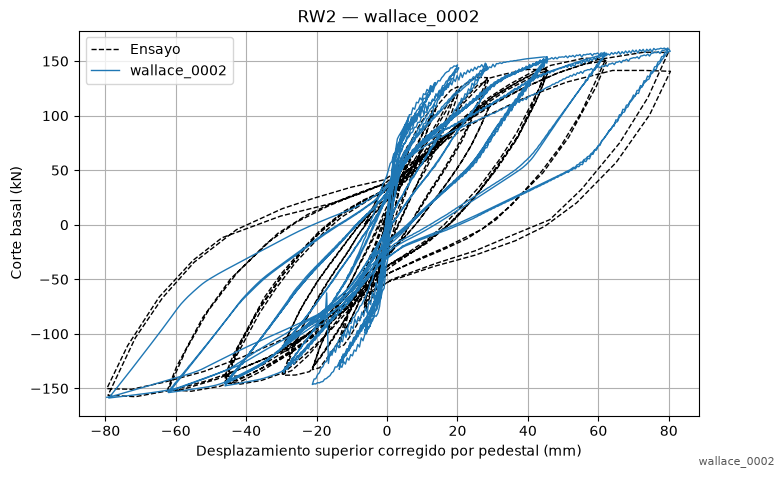

In [12]:
post = rw2.export_global(run_dir, show=True)
results = Results.from_ladruno(str(post.result_path), merge_partitions=True)


## Visor de resultados


In [13]:
results.viewer()

[viewer] notebook kernel detected — spawning the viewer as a separate process so the kernel keeps running (pass blocking=True to open it in-process).


<Popen: returncode: None args: ['c:\\venv\\opensees_venv\\Scripts\\python.ex...>

## SOLO RESULTADOS GUARDADOS - seleccionar corrida

Esta celda funciona desde un kernel nuevo. No construye el modelo ni lanza OpenSees.
Selecciona `ultima_completa`, `ultima` o un identificador como `wallace_0001`.
Si todavía solo existe la importación histórica, se identifica expresamente como tal.


RESULTADOS DE: wallace_0002 completa


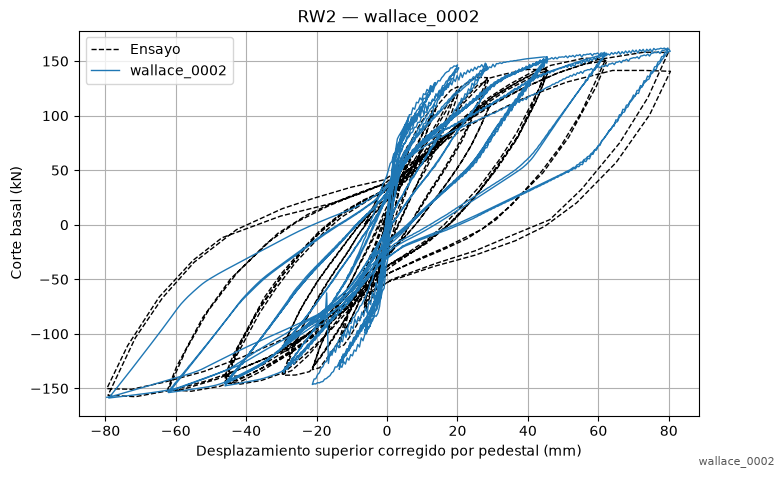

In [14]:
from pathlib import Path
import sys
notebook_dir = Path(r'D:\OneDrive\Escritorio\AHORA SI\Notebooks\RW2_Wallace')
if str(notebook_dir) not in sys.path:
    sys.path.insert(0, str(notebook_dir))
import rw2_workflow as rw2
from apeGmsh import Results

RUN_TO_READ = 'ultima_completa'  # o 'wallace_0001', 'wallace_0002', ...
run_dir = rw2.select_run(notebook_dir, RUN_TO_READ)
print('RESULTADOS DE:', run_dir.name, rw2.metadata(run_dir)['status'])
post = rw2.export_global(run_dir, show=True)
results = Results.from_ladruno(str(post.result_path), merge_partitions=True)


# COMPARACIONES LOCALES - RW2

Bloque independiente de postproceso. Lee la malla, parámetros y respuestas **de la corrida seleccionada**,
sin utilizar valores nuevos de las celdas de materiales. Cada gráfico se guarda en esa misma corrida.
Los CSV experimentales son digitalizaciones de los trazos `Test`; su procedencia y límites están en
[DatosExperimentales/README.md](DatosExperimentales/README.md). La importación histórica no contiene acero ni daño internos.

## L0. Seleccionar corrida y cargar respuestas


In [15]:
from pathlib import Path
import sys
notebook_dir = Path(r'D:\OneDrive\Escritorio\AHORA SI\Notebooks\RW2_Wallace')
if str(notebook_dir) not in sys.path:
    sys.path.insert(0, str(notebook_dir))
import rw2_workflow as rw2

LOCAL_RUN = 'ultima_completa'  # cambiar aquí: por ejemplo 'wallace_0001'
run_dir = rw2.select_run(notebook_dir, LOCAL_RUN)
local_results = rw2.RunResults(run_dir)
print('COMPARACIONES LOCALES:', run_dir.name, '|', local_results.meta['status'])


COMPARACIONES LOCALES: wallace_0002 | completa


## L1. Ubicación de sensores virtuales

Referencia: Fig. 7.10(a), p. impresa 121 / PDF 132. Se usan coordenadas e interpolación
trilineal del sólido, para que una modificación de malla no cambie arbitrariamente los sensores.


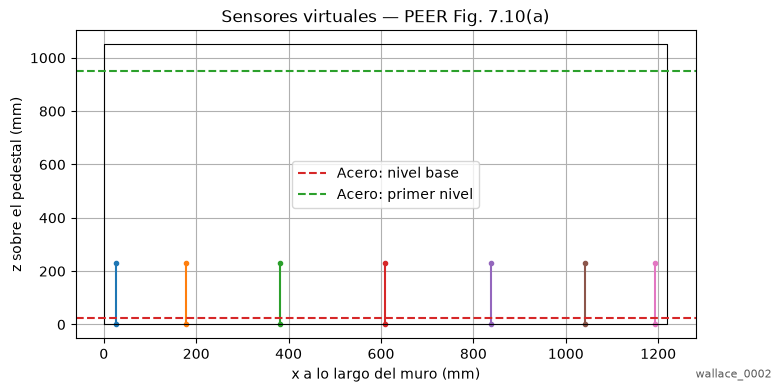

In [16]:
rw2.plot_locations(local_results)


## L2. Hormigón - perfiles de deformación en la base (Fig. 7.30)

P. impresa 145 / PDF 156. Promedio vertical sobre **229 mm**, máximos positivos
a 0.5 %, 1.0 % y 2.0 % de deriva **nominal**. El inicio z=0 mm es un supuesto configurable.
Las derivas se identifican por bloque del protocolo (Tabla 7.3), no por desplazamiento/altura.

El ensayo no identifica el número de ciclo del perfil; `profile_cycle` selecciona el ciclo numérico.


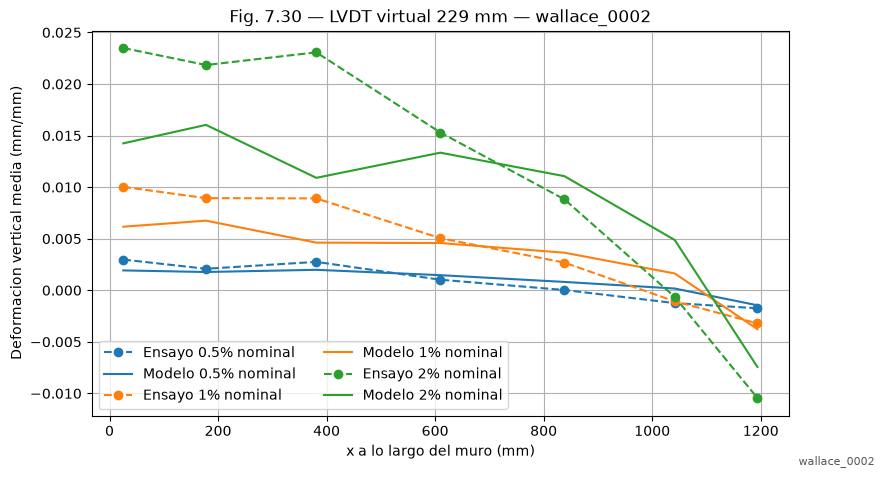

In [17]:
concrete_strains, lvdt_x_mm = rw2.compare_concrete(local_results)


## L3. Acero - perfiles en base y primer nivel (Fig. 7.31)

P. impresa 145 / PDF 156. Respuesta axial de barras a z~25 mm y z~950 mm; se promedian
las dos caras para la representación del perfil. Las corridas antiguas sin registradores internos
muestran la referencia experimental y un aviso; no se inventan deformaciones de barras.


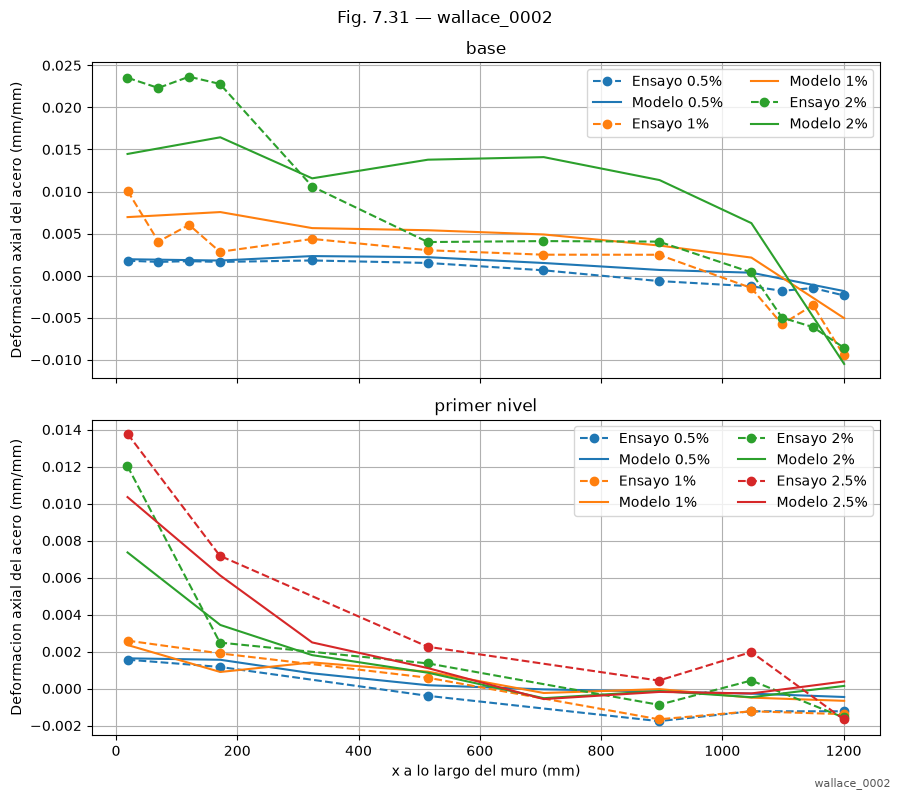

In [18]:
steel_recorded = rw2.compare_steel(local_results)


## L4. Historias de hormigón y rotación (Figs. 7.32 y 7.29)

P. impresas 146 y 144 / PDF 157 y 155. Sensor virtual de hormigón: centro z=92 mm, longitud
83 mm; x=25 mm es un supuesto del borde sur. El sensor embebido falla en el registro 330
y su tracción no es confiable; el LVDT interpolado se limita al registro 515.

El número de registro del informe no es el incremento de OpenSees. Si puede reconstruirse
la secuencia de reversiones se muestra una alineación aproximada, sin métricas punto a punto;
en caso contrario se presentan las historias por separado.


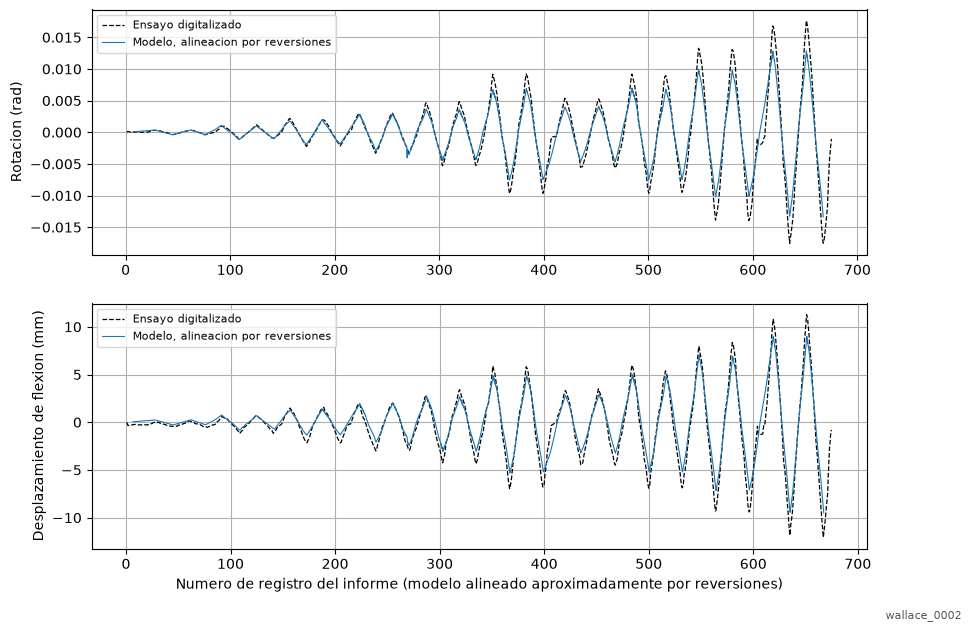

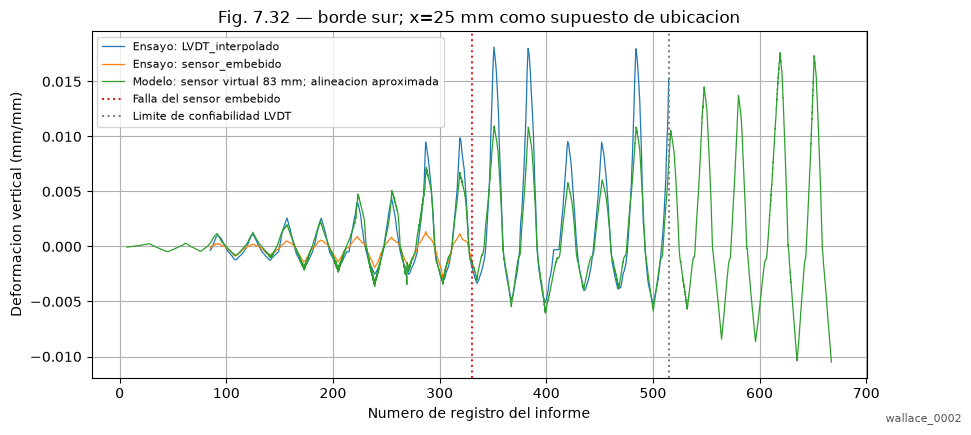

In [19]:
histories_aligned = rw2.compare_histories(local_results)


## L5. Separación flexión-corte por nivel (Figs. 8.3 y 9.3)

P. impresas 160 y 186 / PDF 171 y 196. La comparación utiliza sensores X virtuales y
la corrección de las ecuaciones 8.1-8.2 (alfa=0.67). El ensayo no tenía instrumentos verticales
en el segundo nivel para aplicar esa corrección. Fig. 8.3(a) queda como referencia normalizada
experimental, sin asignar un U_fy desconocido. Las predicciones del informe en Fig. 9.3 eran
monotónicas; aquí se comparan sus trazos experimentales con nuestra respuesta cíclica.


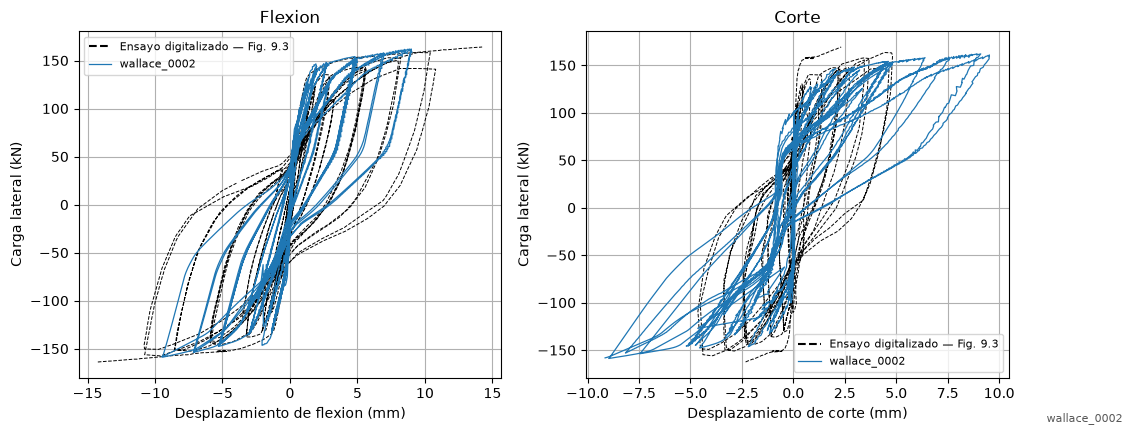

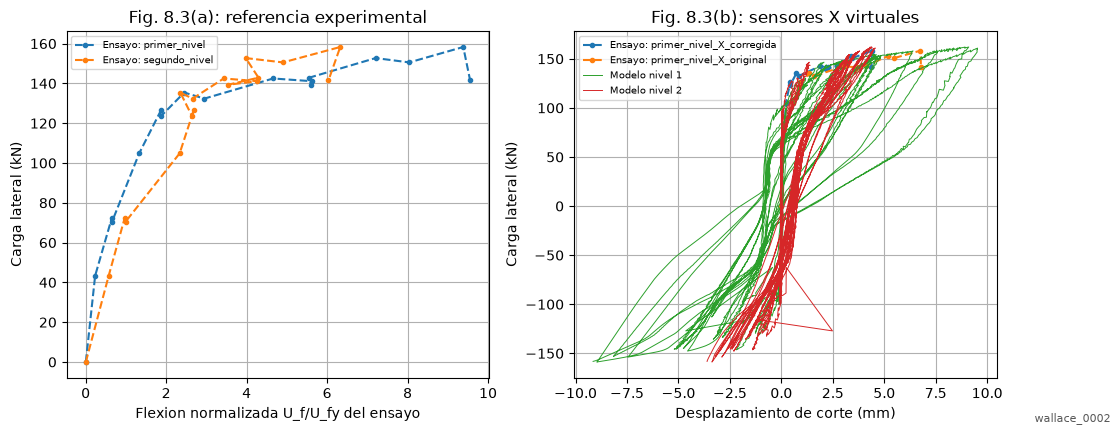

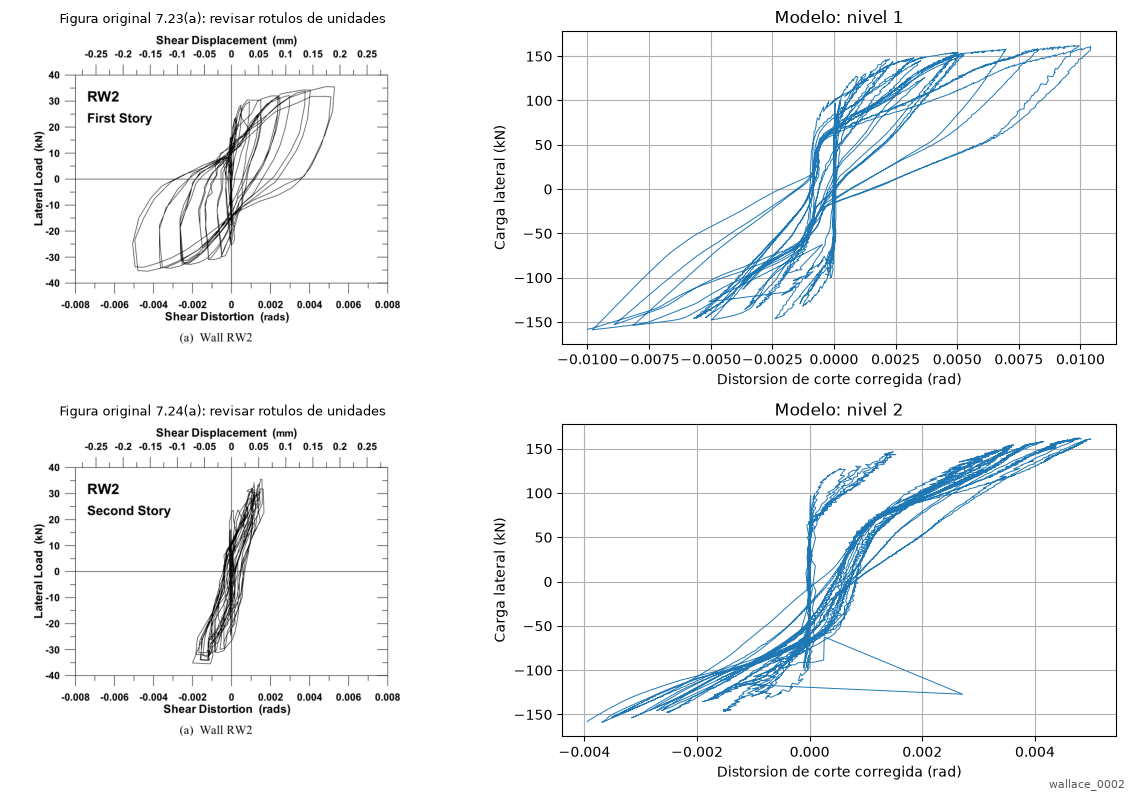

In [20]:
story_components = rw2.compare_kinematics(local_results)


## L6. Perfiles de desplazamiento en altura (Fig. 7.28)

P. impresa 143 / PDF 154. Figura original junto a perfiles numéricos de flexión. Los CSV
contienen los perfiles experimentales digitalizados de los trazos discontinuos `Test` en los niveles 1 a 4.
El origen del nivel 0 se fija geométricamente y se interpolan los espacios entre guiones del PDF.
El ensayo se superpone con líneas discontinuas y marcadores, y el modelo con líneas continuas del mismo color.
El corte en los niveles superiores se extrapola desde el segundo nivel, como en el informe.


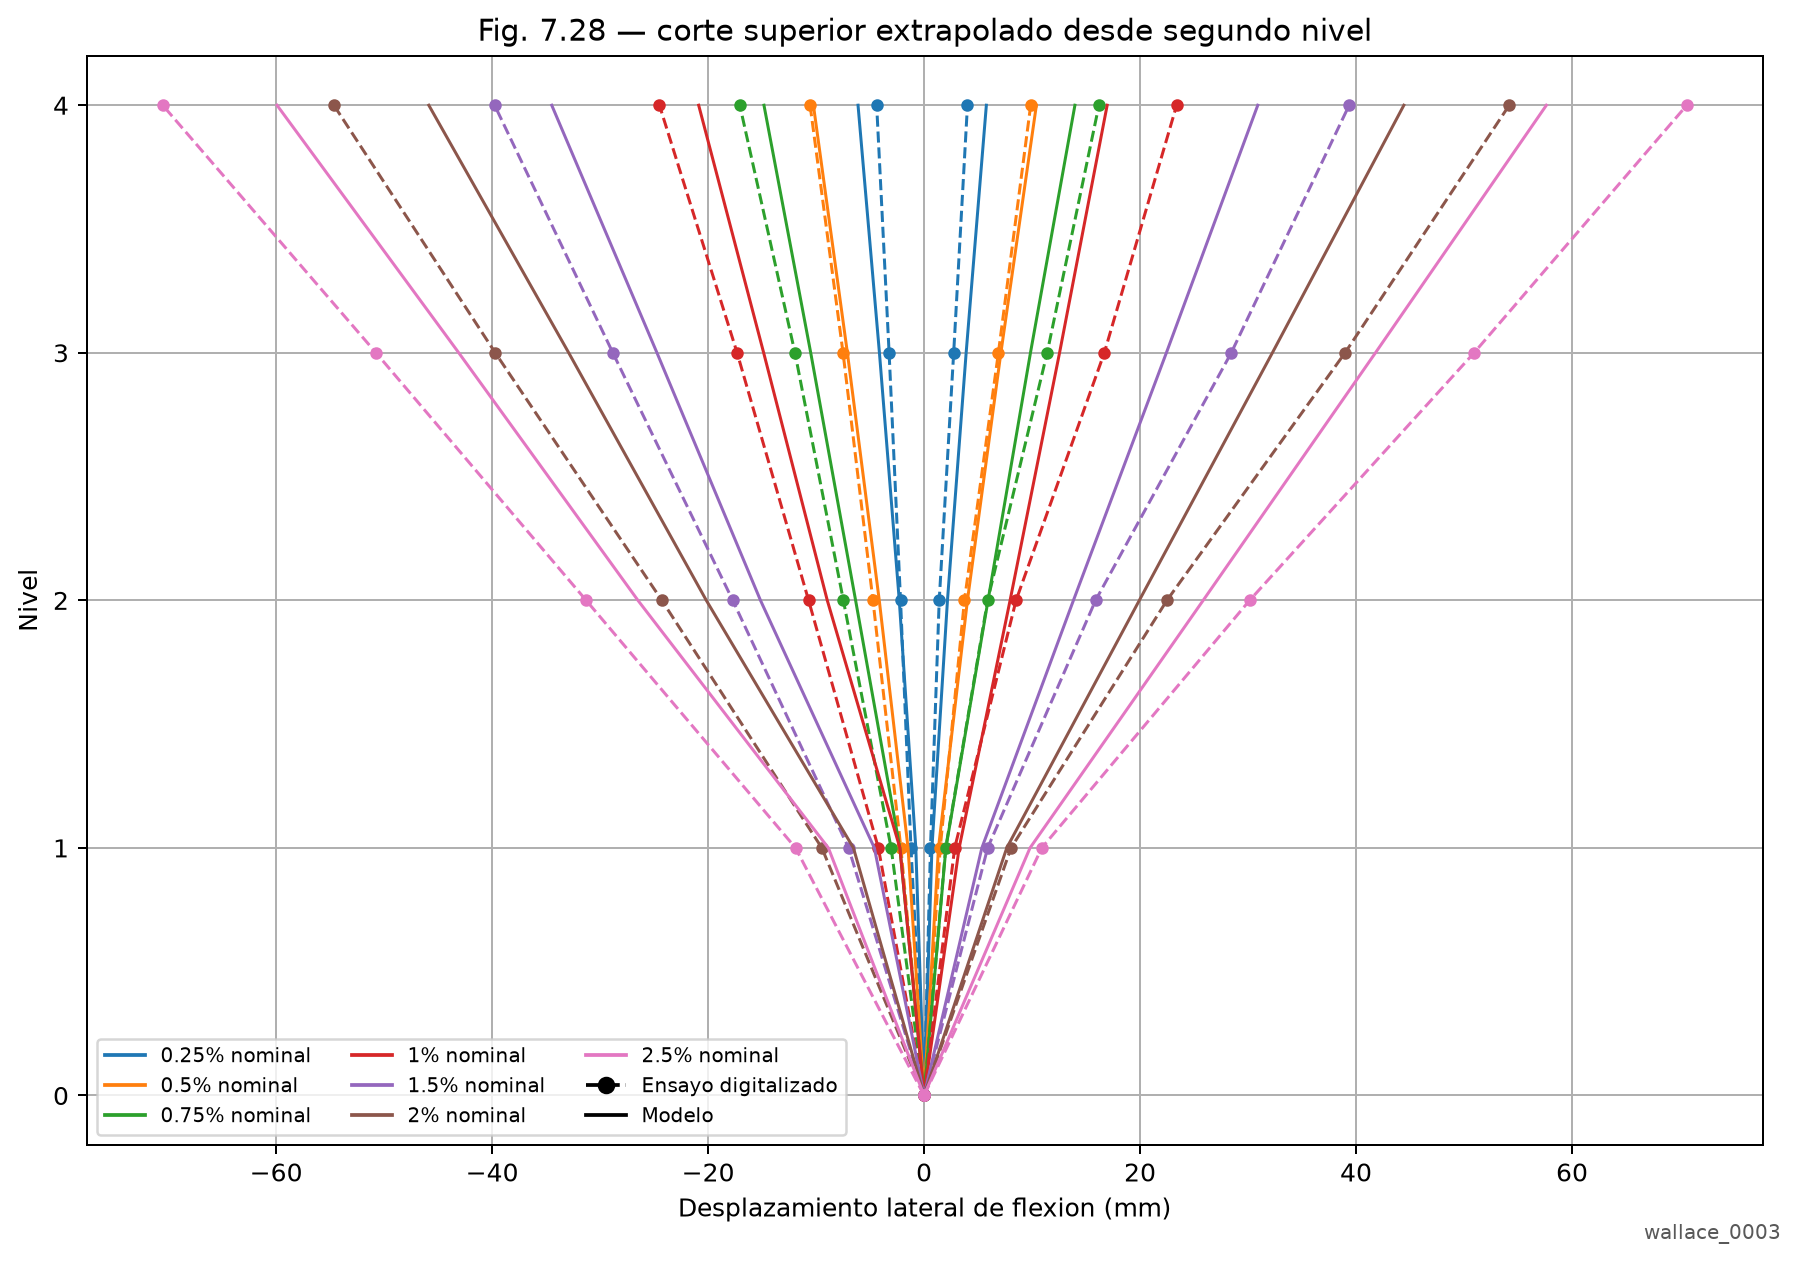

In [21]:
rw2.compare_profiles(local_results)


## L7. Respuestas internas del modelo: tensión-deformación y daño

Exporta las historias de los elementos seleccionados y el mapa de sus identificadores.
Estas variables sirven para interpretar la respuesta numérica; no son mediciones experimentales
de tensiones ni validación de daño. Disponibles únicamente para nuevas corridas con `record_local=True`.


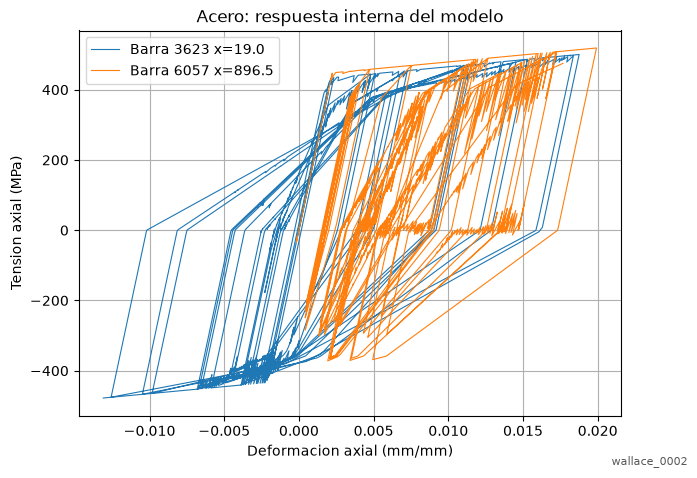

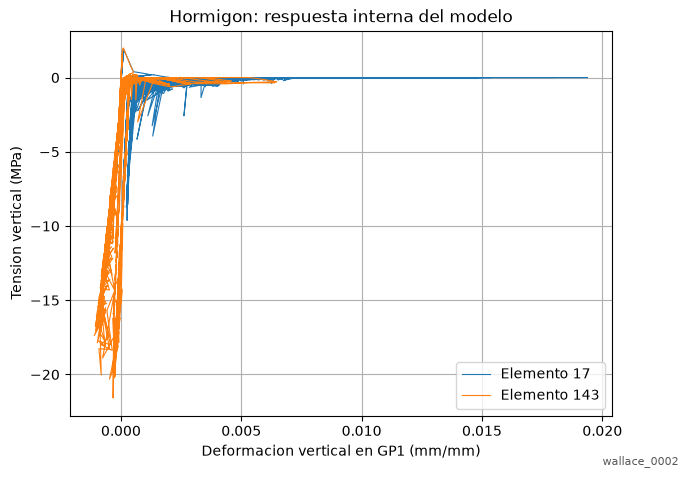

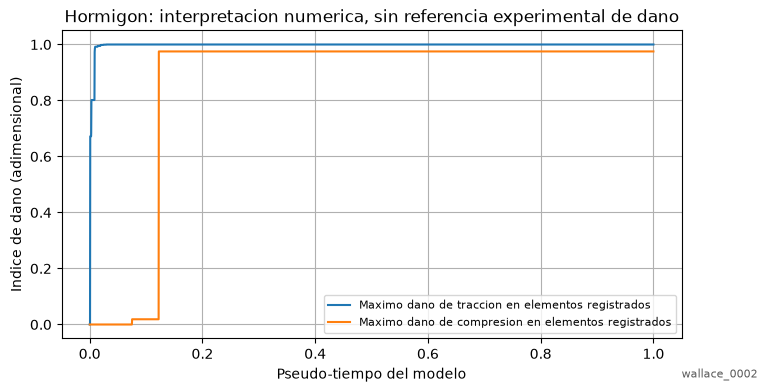

In [22]:
internal_recorded = rw2.export_internal(local_results)


# EXPORTAR Y ACTUALIZAR FICHA DE LA CORRIDA

**Bloque final de exportación.** Funciona de forma independiente, no lanza OpenSees y no crea
un número nuevo. Guarda todos los CSV y gráficos PNG/PDF en la corrida elegida, actualiza
`resumen.md`, `parametros.json` e `indice.md`.

Los parámetros proceden de la captura realizada al generar el modelo. Cambiar valores arriba
no modifica retrospectivamente una corrida archivada.


In [23]:
from pathlib import Path
import sys
notebook_dir = Path(r'D:\OneDrive\Escritorio\AHORA SI\Notebooks\RW2_Wallace')
if str(notebook_dir) not in sys.path:
    sys.path.insert(0, str(notebook_dir))
import rw2_workflow as rw2

RUN_TO_EXPORT = globals().get('LOCAL_RUN', 'ultima_completa')  # o un identificador explícito
export_dir = rw2.select_run(notebook_dir, RUN_TO_EXPORT)
exported_results = rw2.export_all(export_dir, show=False)
from IPython.display import display, Markdown
display(Markdown(f'**{export_dir.name}** - [Abrir ficha](runs/{export_dir.name}/resumen.md) - '
                 f'[Historial](runs/indice.md)'))


Exportacion: D:\OneDrive\Escritorio\AHORA SI\Notebooks\RW2_Wallace\runs\wallace_0002\resumen.md


**wallace_0002** - [Abrir ficha](runs/wallace_0002/resumen.md) - [Historial](runs/indice.md) - [LaTeX](runs/wallace_0002/resumen.tex)